In [ ]:
#Implementation of K-Mean and K-Medoids

final centroids---
Cluster 1 (Centroid: [11.25  9.25]):
  [10.5, 7.5]
  [12.0, 11.0]
Cluster 2 (Centroid: [2.875 2.75 ]):
  [1.5, 2.0]
  [3.0, 1.5]
  [2.5, 4.0]
  [4.5, 3.5]
Cluster 3 (Centroid: [8.16666667 7.16666667]):
  [7.0, 6.5]
  [8.5, 9.0]
  [9.0, 6.0]

final medoids---
Cluster 1 (Medoid: [10.5  7.5]):
  [8.5, 9.0]
  [10.5, 7.5]
  [12.0, 11.0]
Cluster 2 (Medoid: [3.  1.5]):
  [1.5, 2.0]
  [3.0, 1.5]
  [2.5, 4.0]
  [4.5, 3.5]
Cluster 3 (Medoid: [7.  6.5]):
  [7.0, 6.5]
  [9.0, 6.0]



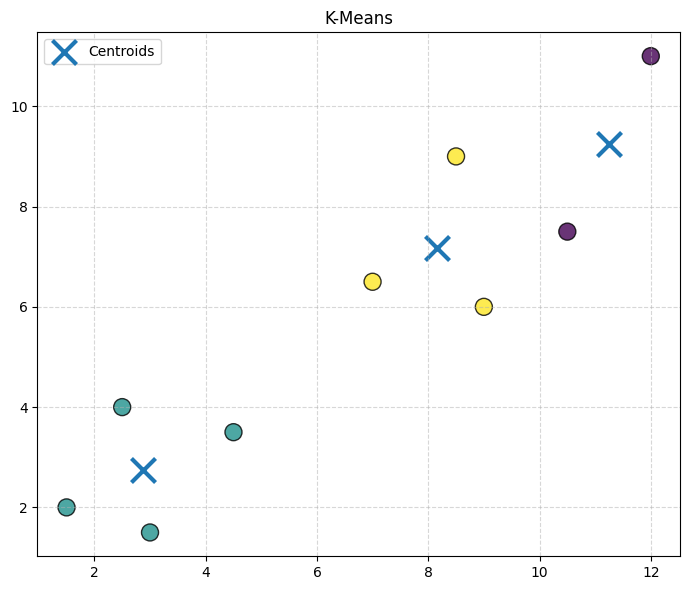

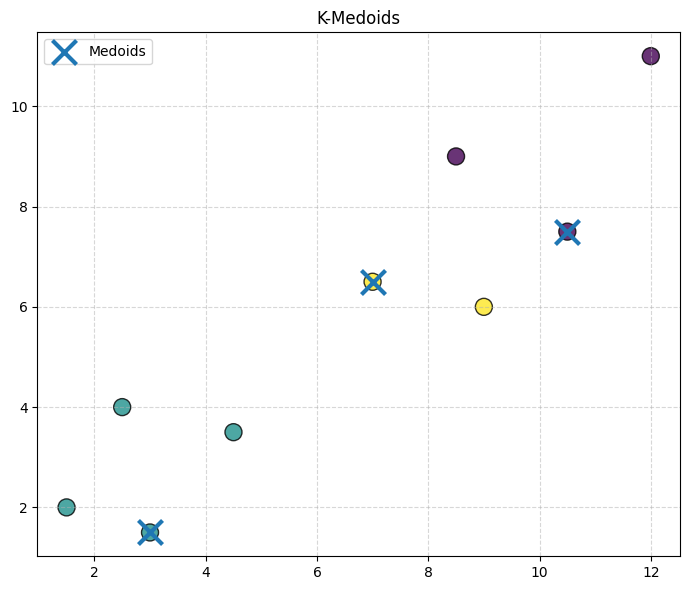

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2, axis=1))

def kmeans(X, k):
    np.random.seed(42)
    centroids = X[np.random.choice(X.shape[0], k, replace=False)]
    for _ in range(10):
        distances = np.array([euclidean_distance(X, centroid) for centroid in centroids])
        labels = np.argmin(distances, axis=0)
        new_centroids = np.array([X[labels == i].mean(axis=0) if len(X[labels == i]) > 0 else centroids[i] for i in range(k)])
        if np.allclose(centroids, new_centroids):
            break
        centroids = new_centroids
    return labels, centroids

def kmedoids(X, k):
    np.random.seed(42)
    medoid_indices = np.random.choice(X.shape[0], k, replace=False)
    medoids = X[medoid_indices]
    for _ in range(10):
        distances = np.array([euclidean_distance(X, medoid) for medoid in medoids])
        labels = np.argmin(distances, axis=0)
        new_medoids = np.copy(medoids)
        for i in range(k):
            cluster_points = X[labels == i]
            if len(cluster_points) == 0:
                continue
            min_cost = float('inf')
            best_medoid = medoids[i]
            for point in cluster_points:
                cost = np.sum(euclidean_distance(cluster_points, point))
                if cost < min_cost:
                    min_cost = cost
                    best_medoid = point
            new_medoids[i] = best_medoid
        if np.allclose(medoids, new_medoids):
            break
        medoids = new_medoids
    return labels, medoids

data = np.array([
    [1.5, 2.0],
    [3.0, 1.5],
    [2.5, 4.0],
    [4.5, 3.5],
    [7.0, 6.5],
    [8.5, 9.0],
    [9.0, 6.0],
    [10.5, 7.5],
    [12.0, 11.0]
])

k_val = 3

k_val = min(k_val, len(np.unique(data, axis=0)))
k_means_labels, kmeans_centroids_new = kmeans(data, k_val)
kmedoids_labels_new, kmedoids_medoids_new = kmedoids(data, k_val)

print("final centroids---")
for cluster_idx in range(k_val):
    cluster_pts = data[k_means_labels == cluster_idx]
    print(f"Cluster {cluster_idx + 1} (Centroid: {kmeans_centroids_new[cluster_idx]}):")
    for pt in cluster_pts:
        print(f"  {pt.tolist()}")
print()

print("final medoids---")
for cluster_idx in range(k_val):
    cluster_pts = data[kmedoids_labels_new == cluster_idx]
    print(f"Cluster {cluster_idx + 1} (Medoid: {kmedoids_medoids_new[cluster_idx]}):")
    for pt in cluster_pts:
        print(f"  {pt.tolist()}")
print()

# K-Means Plot
plt.figure(figsize=(7, 6))
plt.scatter(data[:, 0], data[:, 1], c=k_means_labels, s=150, marker='o', alpha=0.8, edgecolors='black')
plt.scatter(kmeans_centroids_new[:, 0], kmeans_centroids_new[:, 1], s=300, marker='x', linewidths=3, label='Centroids')
plt.title('K-Means')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# K-Medoids Plot
plt.figure(figsize=(7, 6))
plt.scatter(data[:, 0], data[:, 1], c=kmedoids_labels_new, s=150, marker='o', alpha=0.8, edgecolors='black')
plt.scatter(kmedoids_medoids_new[:, 0], kmedoids_medoids_new[:, 1], s=300, marker='x', linewidths=3, label='Medoids')
plt.title('K-Medoids')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [1]:
!pip install scikit-learn-extra

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 819.0/819.0 kB 10.6 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-learn-extra: filename=scikit_learn_extra-0.3.0-cp313-cp313-linux_x86_64.whl size=2156387 sha256=be35c19417abfbf29c16cb0b33014c80ca4c33b8aa83c13398506c1fecb87623
  Stored in directory: /root/.cache/pip/wheels/17/4b/b8/6b6711681d0981b110c9cc91ad6d1ebd88adf1547e1da301fc
Successfully built scikit-learn-extra


In [7]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids

data = np.array([
    [1.5, 2.0],
    [3.0, 1.5],
    [2.5, 4.0],
    [4.5, 3.5],
    [7.0, 6.5],
    [8.5, 9.0],
    [9.0, 6.0],
    [10.5, 7.5],
    [12.0, 11.0]
])

k_val = 3

# K-Means using scikit-learn
kmeans_model = KMeans(n_clusters=k_val, random_state=42, n_init='auto')
kmeans_labels = kmeans_model.fit_predict(data)
kmeans_centroids = kmeans_model.cluster_centers_

# K-Medoids using scikit-learn-extra
kmedoids_model = KMedoids(n_clusters=k_val, random_state=42)
kmedoids_labels = kmedoids_model.fit_predict(data)
kmedoids_centroids = kmedoids_model.cluster_centers_

print("final centroids")
for cluster_idx in range(k_val):
    cluster_pts = data[kmeans_labels == cluster_idx]
    print(f"Cluster {cluster_idx + 1} (Centroid: {kmeans_centroids[cluster_idx]}):")
    print(cluster_pts)
print()

print("final medoids")
for cluster_idx in range(k_val):
    cluster_pts = data[kmedoids_labels == cluster_idx]
    print(f"Cluster {cluster_idx + 1} (Medoid: {kmedoids_centroids[cluster_idx]}):")
    print(cluster_pts)
print()


final centroids
Cluster 1 (Centroid: [8.   6.25]):
[[7.  6.5]
 [9.  6. ]]
Cluster 2 (Centroid: [10.33333333  9.16666667]):
[[ 8.5  9. ]
 [10.5  7.5]
 [12.  11. ]]
Cluster 3 (Centroid: [2.875 2.75 ]):
[[1.5 2. ]
 [3.  1.5]
 [2.5 4. ]
 [4.5 3.5]]

final medoids
Cluster 1 (Medoid: [7.  6.5]):
[[7.  6.5]
 [9.  6. ]]
Cluster 2 (Medoid: [10.5  7.5]):
[[ 8.5  9. ]
 [10.5  7.5]
 [12.  11. ]]
Cluster 3 (Medoid: [3.  1.5]):
[[1.5 2. ]
 [3.  1.5]
 [2.5 4. ]
 [4.5 3.5]]

